# Sentinel-1 LULC Semantic Segmentation: Model Evaluation

## Objective

This notebook evaluates a trained U-Net model for land use and land cover (LULC) semantic segmentation using Sentinel-1 SAR imagery.

The objectives are to:

1. Evaluate the best trained model on an independent test set.
2. Report overall accuracy (OA), mean Intersection over Union (mIoU), and per-class IoU/F1.
3. Analyze the confusion matrix.
4. Visualize predictions alongside SAR imagery and reference labels.
5. Identify typical classification errors and discuss model limitations.

## Dataset Protocol

The original DFC2020 test set was previously divided into training and validation subsets.

The original DFC2020 validation set, containing 986 image-label pairs, is reserved for final independent evaluation.

Only Sentinel-1 VV/VH imagery is used as model input.

The model weights and architecture are fixed before test evaluation. No training or model selection is performed in this notebook.

## Evaluation Protocol

Metrics are calculated from a confusion matrix accumulated over all evaluated pixels, excluding invalid labels.

The official DFC2020 data split has been repurposed for this course project. The results are not directly comparable to the original competition leaderboard.

In [1]:
from pathlib import Path
import os
import sys

path = Path("/home/jovyan/vault/zyang24/sar-lulc-monitor/requirements.txt")

print("Working directory:", os.getcwd())
print("File exists:", path.is_file())
print("Project exists:", path.parent.is_dir())

src_path = Path("/home/jovyan/vault/zyang24/sar-lulc-monitor/src")
sys.path.insert(0, str(src_path))

!pip install -r /home/jovyan/vault/zyang24/sar-lulc-monitor/requirements.txt

Working directory: /home/jovyan/vault/zyang24/sar-lulc-monitor/notebooks
File exists: True
Project exists: True
Defaulting to user installation because normal site-packages is not writeable


In [2]:
import json
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch.utils.data import DataLoader, Subset
from IPython.display import display, Markdown

from sar_lulc_monitor.dataset import create_datasets
from sar_lulc_monitor.model import UNet
from sar_lulc_monitor.metrics import evaluate_segmentation
from sar_lulc_monitor.preprocessing import (
    CLASS_NAMES,
    NUM_CLASSES,
    IGNORE_INDEX,
)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.11.13
PyTorch: 2.9.1+cu128
CUDA available: True
GPU: NVIDIA RTX A6000


In [3]:
# Evaluation configuration

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROJECT_ROOT = Path("/home/jovyan/vault/zyang24/sar-lulc-monitor")

DATA_ROOT = PROJECT_ROOT / "data" / "raw"
OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "evaluation"

# Choose which trained model to evaluate.
RUN_NAME = "unet_full"  # "unet_smoke" or "unet_full"

MODEL_PATH = (
    PROJECT_ROOT / "models" / f"{RUN_NAME}_best.pth"
)

TRAINING_CONFIG_PATH = (
    PROJECT_ROOT / "outputs" / "training"
    / f"{RUN_NAME}_config.json"
)

# None = all test samples.
# Use a small number for local functional testing.
TEST_SAMPLES = None

BATCH_SIZE = 16
NUM_WORKERS = 0
SEED = 42

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

assert MODEL_PATH.is_file(), (
    f"Model checkpoint not found: {MODEL_PATH}"
)

assert TRAINING_CONFIG_PATH.is_file(), (
    f"Training config not found: {TRAINING_CONFIG_PATH}"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Device:", DEVICE)
print("Model:", MODEL_PATH)
print("Data:", DATA_ROOT)
print("Test samples:", TEST_SAMPLES or "ALL")

Device: cuda
Model: /home/jovyan/vault/zyang24/sar-lulc-monitor/models/unet_full_best.pth
Data: /home/jovyan/vault/zyang24/sar-lulc-monitor/data/raw
Test samples: ALL


In [4]:
with open(TRAINING_CONFIG_PATH) as f:
    experiment_info = json.load(f)

print("Training run:", experiment_info["run_name"])
print("Model:", experiment_info["model"])
print("Best epoch:", experiment_info["best_epoch"])
print(
    "Best validation mIoU:",
    experiment_info["best_val_miou"]
)

model_config = {
    "input_channels": experiment_info["input_channels"],
    "num_classes": experiment_info["num_classes"],
    "base_channels": experiment_info["base_channels"],
}

display(pd.DataFrame([
    {"Parameter": key, "Value": value}
    for key, value in model_config.items()
]))

Training run: unet_full
Model: UNet
Best epoch: 49
Best validation mIoU: 0.4935366633222879


,Parameter,Value
0,input_channels,2
1,num_classes,8
2,base_channels,32


In [5]:
from sar_lulc_monitor.dataset import (
    collect_pairs,
    DFCDataset,
)

test_sar_dir = (
    DATA_ROOT
    / "ROIs0000_validation"
    / "s1_validation"
)

test_label_dir = (
    DATA_ROOT
    / "ROIs0000_validation"
    / "dfc_validation"
)

test_pairs = collect_pairs(
    test_sar_dir,
    test_label_dir,
)

test_full = DFCDataset(test_pairs)


def take_test_subset(dataset, sample_count, seed=42):
    if sample_count is None:
        return dataset

    if not 1 <= sample_count <= len(dataset):
        raise ValueError("Invalid test sample count")

    rng = np.random.default_rng(seed)

    indices = rng.choice(
        len(dataset),
        size=sample_count,
        replace=False,
    )

    return Subset(dataset, indices.tolist())


test_dataset = take_test_subset(
    test_full,
    TEST_SAMPLES,
    SEED,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)

print("Total test samples:", len(test_full))
print("Evaluated samples:", len(test_dataset))

sample = test_dataset[0]

print("Image:", sample["image"].shape)
print("Mask:", sample["mask"].shape)

assert sample["image"].shape[0] == 2
assert sample["mask"].ndim == 2

Total test samples: 986
Evaluated samples: 986
Image: torch.Size([2, 256, 256])
Mask: torch.Size([256, 256])


,Class,Pixels,Percentage
0,Forest,5904112,9.136876
1,Shrubland,3353501,5.189692
2,Grassland,7655859,11.847783
3,Wetlands,11272496,17.444690
4,Croplands,8405224,13.007458
5,Urban/Built-up,3517590,5.443627
6,Barren,1887823,2.921490
7,Water,22621891,35.008384


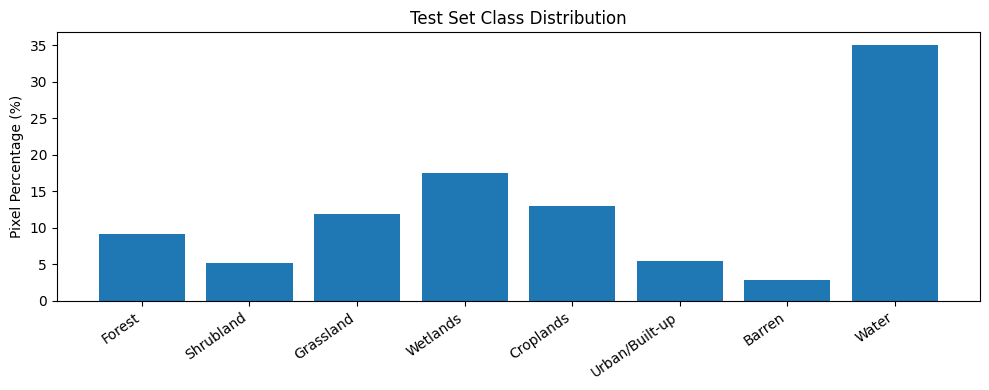

In [6]:
# Distribution of labels
class_counts = np.zeros(NUM_CLASSES, dtype=np.int64)

for batch in test_loader:
    masks = batch["mask"].numpy()

    valid = masks != IGNORE_INDEX

    counts = np.bincount(
        masks[valid].ravel(),
        minlength=NUM_CLASSES,
    )

    class_counts += counts[:NUM_CLASSES]

total_pixels = class_counts.sum()

class_distribution = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Pixels": class_counts,
    "Percentage": class_counts / total_pixels * 100,
})

display(class_distribution)

plt.figure(figsize=(10, 4))

plt.bar(
    class_distribution["Class"],
    class_distribution["Percentage"],
)

plt.title("Test Set Class Distribution")
plt.ylabel("Pixel Percentage (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [7]:
model = UNet(
    in_channels=model_config["input_channels"],
    num_classes=model_config["num_classes"],
    base_channels=model_config["base_channels"],
).to(DEVICE)

state_dict = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=True,
)

model.load_state_dict(state_dict)
model.eval()

params = sum(
    p.numel()
    for p in model.parameters()
)

print("Model loaded successfully.")
print(f"Parameters: {params:,}")
print("Device:", DEVICE)

Model loaded successfully.
Parameters: 1,948,232
Device: cuda


## Quantitative Evaluation

The model is evaluated on the independent DFC2020 test set.

The following metrics are reported:

- **Overall Accuracy (OA):** Fraction of correctly classified valid pixels.
- **Intersection over Union (IoU):** Intersection divided by union for each class.
- **Mean IoU (mIoU):** Macro-average of per-class IoU.
- **F1 Score:** Harmonic mean of precision and recall for each class.

Metrics are computed from the confusion matrix accumulated over the entire evaluation set.

Invalid reference pixels (ignore index 255) are excluded.

Classes absent from both the reference labels and predictions are excluded from macro-averaging.

Class imbalance is considered when interpreting overall accuracy and per-class performance.

In [8]:
results = evaluate_segmentation(
    model=model,
    loader=test_loader,
    device=DEVICE,
    num_classes=NUM_CLASSES,
    ignore_index=IGNORE_INDEX,
)

oa = results["oa"]
miou = results["miou"]

print(f"Overall Accuracy: {oa:.4f}")
print(f"Mean IoU: {miou:.4f}")

class_metrics = pd.DataFrame({
    "Class": CLASS_NAMES,
    "IoU": results["per_class_iou"],
    "F1": results["per_class_f1"],
    "Support": results["confusion_matrix"].sum(axis=1),
})

display(class_metrics.round(4))

Overall Accuracy: 0.5888
Mean IoU: 0.3416


,Class,IoU,F1,Support
0,Forest,0.5221,0.6860,5904112
1,Shrubland,0.1288,0.2282,3353501
2,Grassland,0.0042,0.0084,7655859
3,Wetlands,0.0029,0.0059,11272496
4,Croplands,0.2895,0.4490,8405224
5,Urban/Built-up,0.5950,0.7461,3517590
6,Barren,0.2211,0.3622,1887823
7,Water,0.9691,0.9843,22621891


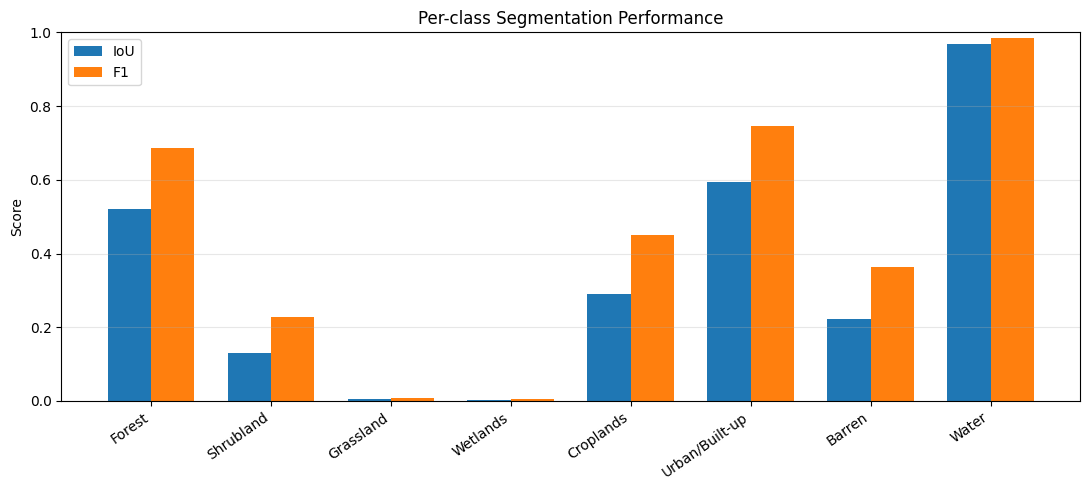

In [9]:
# Per-class performance visualization
x = np.arange(NUM_CLASSES)
width = 0.36

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    x - width / 2,
    class_metrics["IoU"],
    width,
    label="IoU",
)

ax.bar(
    x + width / 2,
    class_metrics["F1"],
    width,
    label="F1",
)

ax.set_xticks(x)
ax.set_xticklabels(
    CLASS_NAMES,
    rotation=35,
    ha="right",
)

ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_title("Per-class Segmentation Performance")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_ROOT / f"{RUN_NAME}_per_class_metrics.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

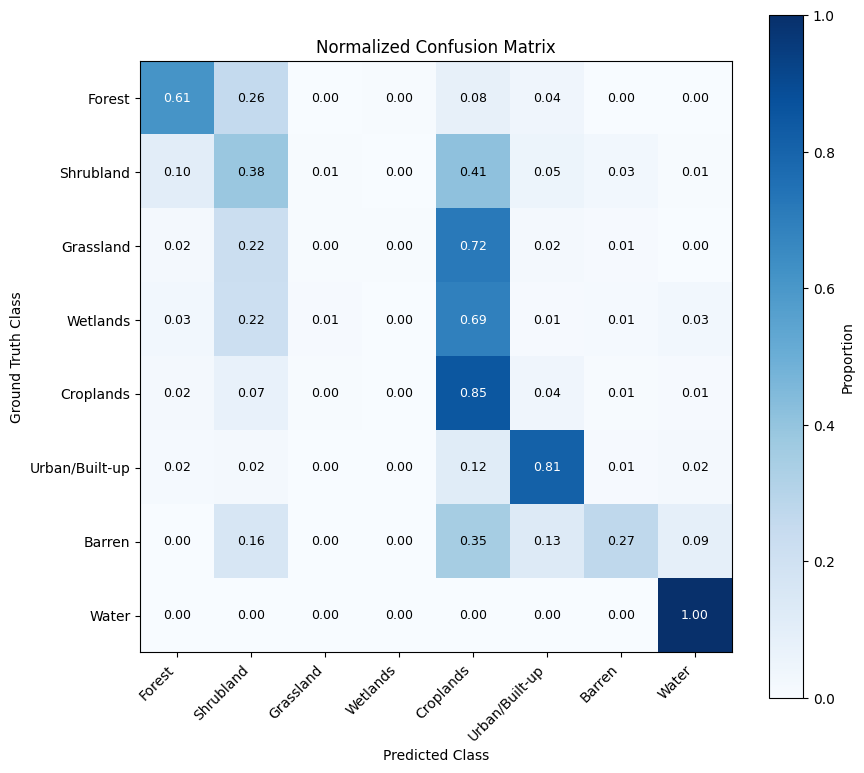

In [10]:
# Confusion matrix
cm = results["confusion_matrix"]

row_sums = cm.sum(axis=1, keepdims=True)

cm_normalized = np.divide(
    cm,
    row_sums,
    out=np.zeros_like(cm, dtype=float),
    where=row_sums != 0,
)

fig, ax = plt.subplots(figsize=(9, 8))

im = ax.imshow(
    cm_normalized,
    cmap="Blues",
    vmin=0,
    vmax=1,
)

ax.set_xticks(np.arange(NUM_CLASSES))
ax.set_yticks(np.arange(NUM_CLASSES))

ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticklabels(CLASS_NAMES)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("Ground Truth Class")
ax.set_title("Normalized Confusion Matrix")

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        value = cm_normalized[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value > 0.5 else "black",
            fontsize=9,
        )

fig.colorbar(im, ax=ax, label="Proportion")

plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT / f"{RUN_NAME}_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [11]:
confusions = []

for true_id in range(NUM_CLASSES):
    for pred_id in range(NUM_CLASSES):
        if true_id == pred_id:
            continue

        count = cm[true_id, pred_id]
        support = cm[true_id].sum()

        if support == 0:
            continue

        confusions.append({
            "Ground Truth": CLASS_NAMES[true_id],
            "Predicted As": CLASS_NAMES[pred_id],
            "Pixels": int(count),
            "Rate (%)": float(count / support * 100),
        })

confusion_df = pd.DataFrame(confusions)

confusion_df = confusion_df.sort_values(
    "Pixels", ascending=False
)

display(confusion_df.head(10))

,Ground Truth,Predicted As,Pixels,Rate (%)
24,Wetlands,Croplands,7782978,69.043963
17,Grassland,Croplands,5498466,71.820367
22,Wetlands,Shrubland,2431214,21.567663
15,Grassland,Shrubland,1712701,22.371115
0,Forest,Shrubland,1514436,25.650530
10,Shrubland,Croplands,1386320,41.339484
46,Barren,Croplands,663324,35.136981
29,Croplands,Shrubland,604598,7.193122
3,Forest,Croplands,471429,7.984757
39,Urban/Built-up,Croplands,407995,11.598708


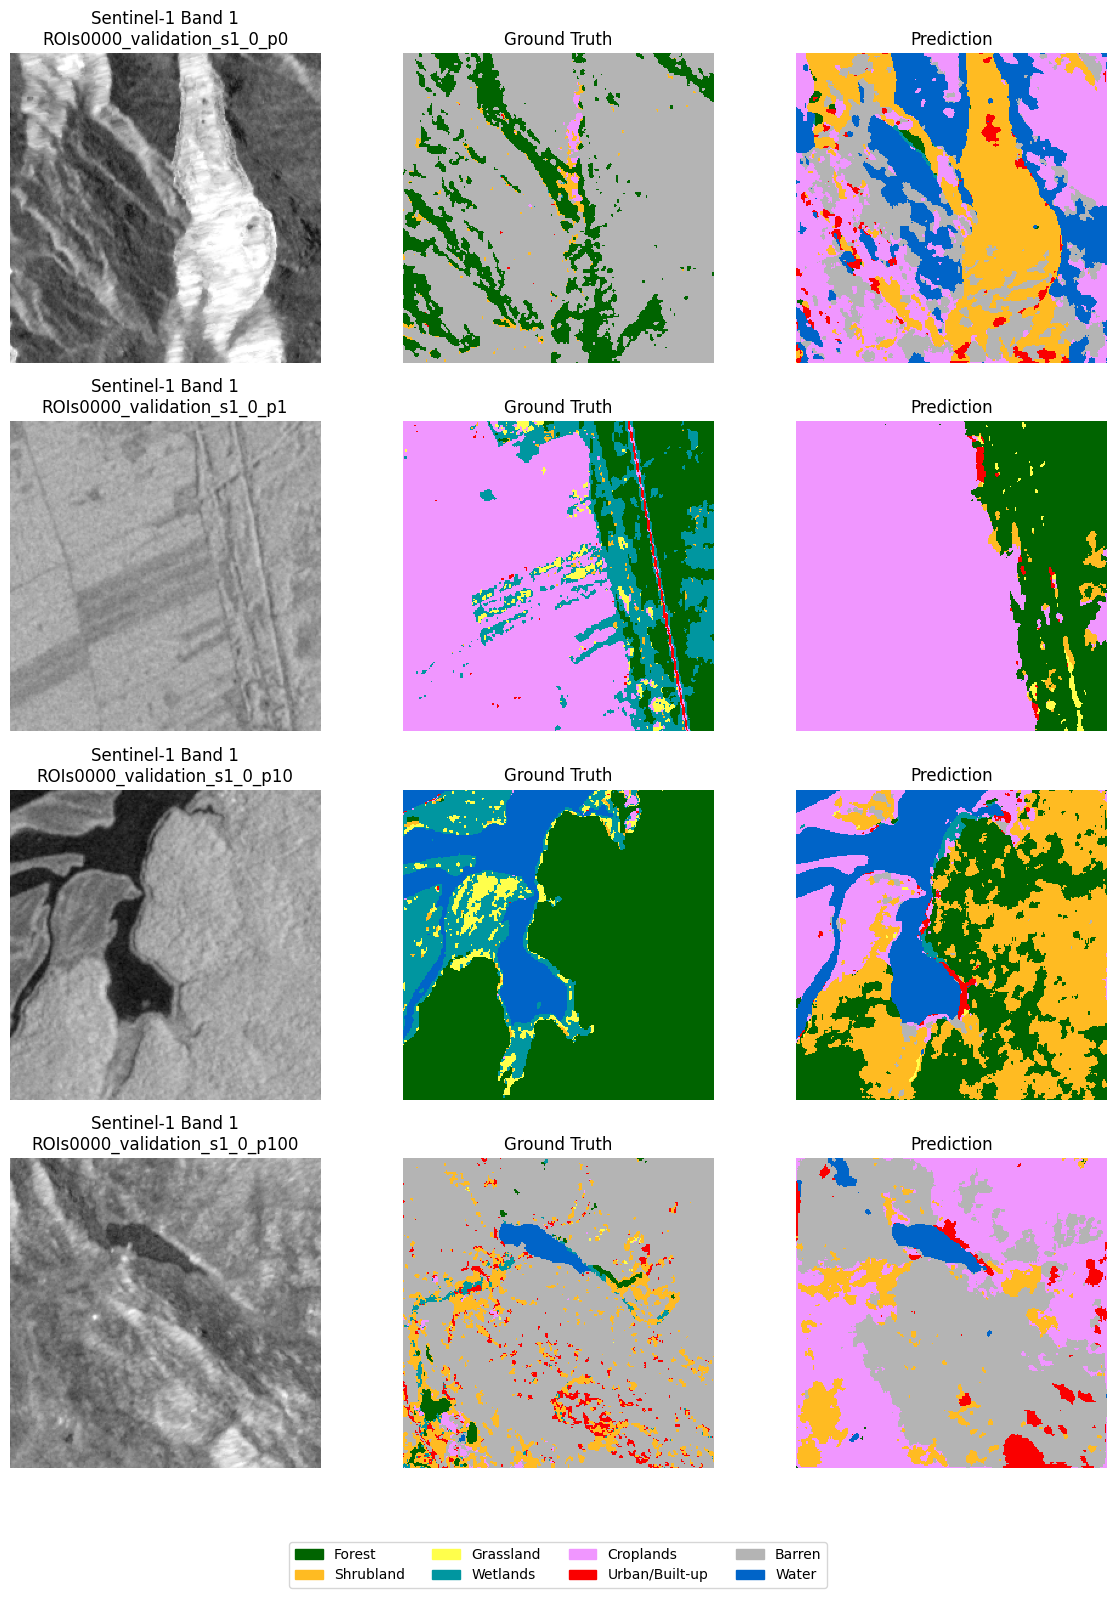

In [12]:
# Visualize predictions
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

CLASS_COLORS = [
    "#006400",  # Forest
    "#ffbb22",  # Shrubland
    "#ffff4c",  # Grassland
    "#0096a0",  # Wetlands
    "#f096ff",  # Croplands
    "#fa0000",  # Urban/Built-up
    "#b4b4b4",  # Barren
    "#0064c8",  # Water
]

cmap = ListedColormap(CLASS_COLORS)
norm = BoundaryNorm(
    np.arange(NUM_CLASSES + 1) - 0.5,
    NUM_CLASSES,
)

legend_items = [
    Patch(color=CLASS_COLORS[i], label=CLASS_NAMES[i])
    for i in range(NUM_CLASSES)
]


@torch.inference_mode()
def plot_predictions(
    model,
    dataset,
    indices,
    device,
):
    model.eval()

    fig, axes = plt.subplots(
        len(indices),
        3,
        figsize=(12, 4 * len(indices)),
        squeeze=False,
    )

    for row, idx in enumerate(indices):
        sample = dataset[idx]

        image = sample["image"]
        label = sample["mask"].numpy()

        logits = model(
            image.unsqueeze(0).to(device)
        )

        prediction = (
            logits.argmax(dim=1)[0]
            .cpu().numpy()
        )

        axes[row, 0].imshow(
            image[0].numpy(),
            cmap="gray",
            vmin=0, vmax=1,
        )

        axes[row, 1].imshow(
            np.ma.masked_where(
                label == IGNORE_INDEX, label
            ),
            cmap=cmap,
            norm=norm,
            interpolation="nearest",
        )

        axes[row, 2].imshow(
            prediction,
            cmap=cmap,
            norm=norm,
            interpolation="nearest",
        )

        axes[row, 0].set_title(
            f"Sentinel-1 Band 1\n{sample['id']}"
        )
        axes[row, 1].set_title("Ground Truth")
        axes[row, 2].set_title("Prediction")

        for ax in axes[row]:
            ax.axis("off")

    fig.legend(
        handles=legend_items,
        loc="lower center",
        ncol=4,
        bbox_to_anchor=(0.5, 0.0),
    )

    plt.tight_layout(rect=(0, 0.07, 1, 1))
    plt.show()


plot_predictions(
    model=model,
    dataset=test_dataset,
    indices=list(range(min(4, len(test_dataset)))),
    device=DEVICE,
)

In [13]:
# Analyze prediction errors
@torch.inference_mode()
def rank_samples_by_accuracy(
    model,
    loader,
    device,
    ignore_index=255,
):
    model.eval()
    scores = []

    for batch in loader:
        images = batch["image"].to(device)
        masks = batch["mask"].to(device)

        predictions = model(images).argmax(dim=1)

        for i in range(images.shape[0]):
            valid = masks[i] != ignore_index

            if valid.sum().item() == 0:
                continue

            accuracy = (
                (predictions[i][valid] == masks[i][valid])
                .float().mean().item()
            )

            scores.append({
                "id": batch["id"][i],
                "accuracy": accuracy,
            })

    return pd.DataFrame(scores).sort_values(
        "accuracy", ascending=True
    ).reset_index(drop=True)


sample_scores = rank_samples_by_accuracy(
    model, test_loader, DEVICE,
    ignore_index=IGNORE_INDEX,
)

display(sample_scores.head(10))

,id,accuracy
0,ROIs0000_validation_s1_0_p189,0.000015
1,ROIs0000_validation_s1_0_p561,0.000137
2,ROIs0000_validation_s1_0_p613,0.000137
3,ROIs0000_validation_s1_0_p858,0.000259
4,ROIs0000_validation_s1_0_p398,0.000351
5,ROIs0000_validation_s1_0_p229,0.000397
6,ROIs0000_validation_s1_0_p238,0.000748
7,ROIs0000_validation_s1_0_p817,0.000778
8,ROIs0000_validation_s1_0_p92,0.001129
9,ROIs0000_validation_s1_0_p851,0.001221


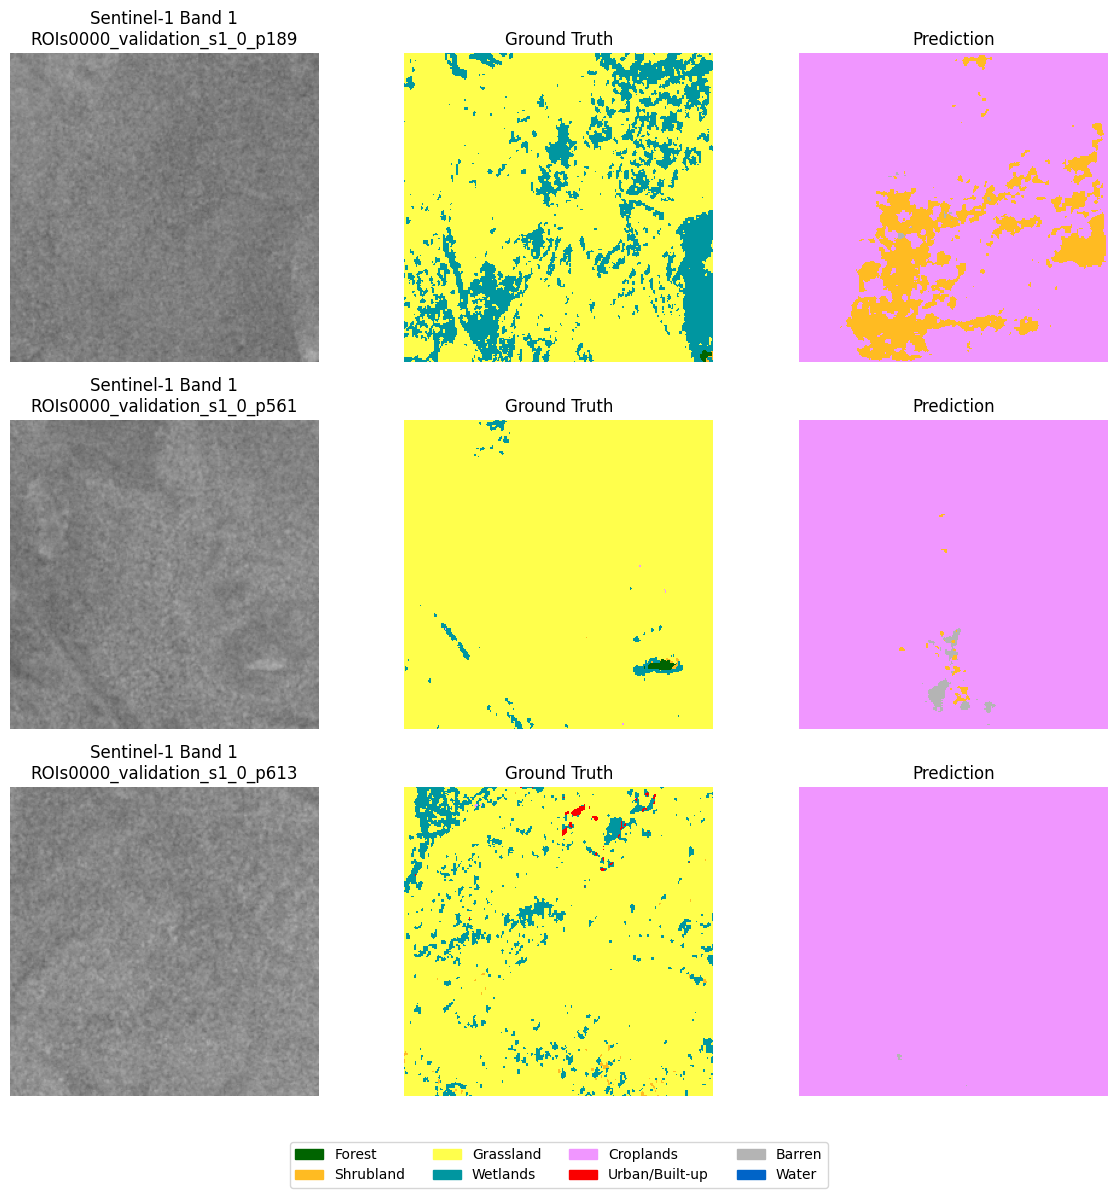

In [14]:
# 3 samples with the lowest accuracy
id_to_index = {
    test_dataset[i]["id"]: i
    for i in range(len(test_dataset))
}

worst_ids = sample_scores["id"].head(3).tolist()
worst_indices = [id_to_index[sid] for sid in worst_ids]

plot_predictions(
    model=model,
    dataset=test_dataset,
    indices=worst_indices,
    device=DEVICE,
)

In [15]:
# Report
METRICS_PATH = OUTPUT_ROOT / f"{RUN_NAME}_metrics.json"
CLASS_CSV_PATH = OUTPUT_ROOT / f"{RUN_NAME}_per_class.csv"
CM_CSV_PATH = OUTPUT_ROOT / f"{RUN_NAME}_confusion_matrix.csv"

summary = {
    "model": RUN_NAME,
    "checkpoint": str(MODEL_PATH),
    "evaluated_samples": len(test_dataset),
    "total_test_samples": len(test_full),
    "overall_accuracy": float(oa),
    "mean_iou": float(miou),
    "class_names": list(CLASS_NAMES),
    "per_class_iou": [
        float(v) if np.isfinite(v) else None
        for v in results["per_class_iou"]
    ],
    "per_class_f1": [
        float(v) if np.isfinite(v) else None
        for v in results["per_class_f1"]
    ],
}

with open(METRICS_PATH, "w") as f:
    json.dump(summary, f, indent=2)

class_metrics.to_csv(CLASS_CSV_PATH, index=False)

pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES,
).to_csv(CM_CSV_PATH)

print("Saved files:")
print(METRICS_PATH)
print(CLASS_CSV_PATH)
print(CM_CSV_PATH)

Saved files:
/home/jovyan/vault/zyang24/sar-lulc-monitor/outputs/evaluation/unet_full_metrics.json
/home/jovyan/vault/zyang24/sar-lulc-monitor/outputs/evaluation/unet_full_per_class.csv
/home/jovyan/vault/zyang24/sar-lulc-monitor/outputs/evaluation/unet_full_confusion_matrix.csv


In [16]:
display(Markdown(f"""
## Evaluation Results Summary

| Item | Result |
|---|---|
| Model | Lightweight U-Net |
| Input | Sentinel-1 VV/VH |
| LULC classes | {NUM_CLASSES} |
| Test dataset | Original DFC2020 validation set |
| Evaluated patches | {len(test_dataset)} |
| Overall Accuracy | {oa:.4f} |
| Mean IoU | {miou:.4f} |
| Best training epoch | {experiment_info["best_epoch"]} |
| Best validation mIoU | {experiment_info["best_val_miou"]:.4f} |

The trained model was evaluated without further parameter updates.

Evaluation includes per-class IoU/F1, class confusion,
and qualitative comparisons between reference labels
and model predictions.
"""))


## Evaluation Results Summary

| Item | Result |
|---|---|
| Model | Lightweight U-Net |
| Input | Sentinel-1 VV/VH |
| LULC classes | 8 |
| Test dataset | Original DFC2020 validation set |
| Evaluated patches | 986 |
| Overall Accuracy | 0.5888 |
| Mean IoU | 0.3416 |
| Best training epoch | 49 |
| Best validation mIoU | 0.4935 |

The trained model was evaluated without further parameter updates.

Evaluation includes per-class IoU/F1, class confusion,
and qualitative comparisons between reference labels
and model predictions.
